In [1]:

# TB Optimization Setup

from google.colab import drive
from pathlib import Path
import torch
import pandas as pd

drive.mount("/content/drive")

BASE = Path("/content/drive/MyDrive/Major_Project/Tuberculosis")
OUTPUT_DIR = BASE / "outputs"
OPT_DIR = OUTPUT_DIR / "optimization"
MODEL_DIR = OPT_DIR / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Load Original Dataset Splits
train_df = pd.read_csv(OUTPUT_DIR / "tb_train.csv")
val_df = pd.read_csv(OUTPUT_DIR / "tb_val.csv")
test_df = pd.read_csv(OUTPUT_DIR / "tb_test.csv")

# Verify Baseline Checkpoint
baseline_path = OUTPUT_DIR / "models" / "tb_densenet121_best.pth"

# Device Verification
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nDataset splits:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nBaseline checkpoint exists:", baseline_path.exists())
print("Optimization output directory:", OPT_DIR)


Mounted at /content/drive
Device: cuda
GPU: NVIDIA L4

Dataset splits:
Training: 463
Validation: 99
Test: 100

Baseline checkpoint exists: True
Optimization output directory: /content/drive/MyDrive/Major_Project/Tuberculosis/outputs/optimization


In [2]:

# TB Dataset and DataLoaders

import sys
import torch
import pandas as pd

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Import Original TB Preprocessing
sys.path.insert(0, str(OUTPUT_DIR))

from tb_preprocessing import preprocess_tb_image

# ImageNet Normalization
tb_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# TB Dataset
class TBDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image = preprocess_tb_image(row["image_path"])
        label = int(row["label"])

        image = self.transform(image)

        return image, label


# Datasets
train_dataset = TBDataset(train_df, tb_transform)
val_dataset = TBDataset(val_df, tb_transform)

# DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

# Verify Batch
images, labels = next(iter(train_loader))

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Label values:", sorted(set(labels.tolist())))
print("Device:", device)


Training images: 463
Validation images: 99
Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Label values: [0, 1]
Device: cuda


In [3]:

# DenseNet-121 Hyperparameter Search Configuration

import random
import numpy as np
import torch
import torch.nn as nn

from torchvision.models import densenet121, DenseNet121_Weights

# Reproducibility
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

# Hyperparameter Search Space
learning_rates = [3e-5, 1e-4, 3e-4]

weight_decay = 1e-4
max_epochs = 10
batch_size = 16

# Model Factory
def create_tb_densenet():
    model = densenet121(
        weights=DenseNet121_Weights.DEFAULT
    )

    num_features = model.classifier.in_features
    model.classifier = nn.Linear(num_features, 2)

    return model.to(device)

# Mixed Precision
use_amp = device.type == "cuda"

# Verify Configuration
print("Model: DenseNet-121")
print("Learning rates:", learning_rates)
print("Weight decay:", weight_decay)
print("Maximum epochs:", max_epochs)
print("Batch size:", batch_size)
print("Mixed precision:", use_amp)
print("Device:", device)

print("\nOriginal baseline validation AUROC: 0.9482")


Model: DenseNet-121
Learning rates: [3e-05, 0.0001, 0.0003]
Weight decay: 0.0001
Maximum epochs: 10
Batch size: 16
Mixed precision: True
Device: cuda

Original baseline validation AUROC: 0.9482


In [4]:
# TB DenseNet-121 Learning Rate Search

import gc
import json
import random
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score, accuracy_score

def restore_optimizer_device(optimizer, device):
    for state in optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value):
                state[key] = value.to(device)

def train_lr_trial(lr):

    # Trial Setup
    trial_name = f"lr_{lr:.0e}"
    trial_dir = OPT_DIR / trial_name
    trial_dir.mkdir(parents=True, exist_ok=True)

    best_path = trial_dir / "best_model.pth"
    resume_path = trial_dir / "resume_checkpoint.pth"
    history_path = trial_dir / "training_history.csv"
    summary_path = trial_dir / "summary.json"

    if summary_path.exists():
        with open(summary_path) as f:
            summary = json.load(f)
        if summary.get("status") == "completed":
            print(f"\nSkipping completed trial: {trial_name}")
            return summary

    # Reproducible Initialization
    set_seed(SEED)

    model = create_tb_densenet()
    criterion = torch.nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=max_epochs
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=use_amp
    )

    best_auc = -1.0
    best_epoch = 0
    start_epoch = 1
    history = []

    # Resume Trial
    if resume_path.exists():
        checkpoint = torch.load(
            resume_path,
            map_location=device,
            weights_only=False
        )

        model.load_state_dict(checkpoint["model"])
        optimizer.load_state_dict(checkpoint["optimizer"])
        restore_optimizer_device(optimizer, device)
        scheduler.load_state_dict(checkpoint["scheduler"])
        scaler.load_state_dict(checkpoint["scaler"])

        best_auc = checkpoint["best_auc"]
        best_epoch = checkpoint["best_epoch"]
        start_epoch = checkpoint["epoch"] + 1
        history = checkpoint["history"]

        if "rng_state" in checkpoint:
            torch.set_rng_state(checkpoint["rng_state"].cpu())

        if device.type == "cuda" and "cuda_rng_state" in checkpoint:
            torch.cuda.set_rng_state_all(checkpoint["cuda_rng_state"])

        print(f"\nResuming {trial_name} at epoch {start_epoch}")

    else:
        print(f"\nStarting trial: {trial_name}")

    # Epoch Loop
    for epoch in range(start_epoch, max_epochs + 1):

        model.train()
        train_loss_sum = 0.0
        train_correct = 0
        train_total = 0

        train_bar = tqdm(
            train_loader,
            desc=f"{trial_name} | Epoch {epoch}/{max_epochs} Train",
            leave=False
        )

        # Training
        for images, labels in train_bar:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type=device.type,
                enabled=use_amp
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            batch_size_actual = labels.size(0)

            train_loss_sum += loss.item() * batch_size_actual
            train_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            train_total += batch_size_actual

            train_bar.set_postfix(
                loss=f"{train_loss_sum / train_total:.3f}",
                acc=f"{train_correct / train_total:.3f}"
            )

        # Validation
        model.eval()
        val_labels = []
        val_probs = []

        val_bar = tqdm(
            val_loader,
            desc=f"{trial_name} | Epoch {epoch}/{max_epochs} Val",
            leave=False
        )

        with torch.inference_mode():
            for images, labels in val_bar:
                images = images.to(device, non_blocking=True)

                with torch.autocast(
                    device_type=device.type,
                    enabled=use_amp
                ):
                    outputs = model(images)

                probabilities = torch.softmax(
                    outputs.float(), dim=1
                )[:, 1]

                val_labels.extend(labels.numpy())
                val_probs.extend(probabilities.cpu().numpy())

        val_labels = np.array(val_labels)
        val_probs = np.array(val_probs)

        val_auc = roc_auc_score(val_labels, val_probs)
        val_acc = accuracy_score(
            val_labels,
            (val_probs >= 0.5).astype(int)
        )

        # Best Checkpoint
        if val_auc > best_auc:
            best_auc = float(val_auc)
            best_epoch = epoch

            torch.save(model.state_dict(), best_path)

            print(
                f"  Best checkpoint saved | "
                f"Epoch {epoch} | AUROC {best_auc:.4f}"
            )

        # Training History
        history.append({
            "epoch": epoch,
            "learning_rate": lr,
            "train_loss": train_loss_sum / train_total,
            "train_accuracy": train_correct / train_total,
            "val_accuracy": val_acc,
            "val_auroc": val_auc
        })

        pd.DataFrame(history).to_csv(
            history_path,
            index=False
        )

        scheduler.step()

        # Resume Checkpoint
        checkpoint = {
            "epoch": epoch,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(),
            "scaler": scaler.state_dict(),
            "best_auc": best_auc,
            "best_epoch": best_epoch,
            "history": history,
            "rng_state": torch.get_rng_state(),
        }

        if device.type == "cuda":
            checkpoint["cuda_rng_state"] = (
                torch.cuda.get_rng_state_all()
            )

        torch.save(checkpoint, resume_path)

        print(
            f"{trial_name} | Epoch {epoch}/{max_epochs} | "
            f"Train Acc: {train_correct / train_total:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Val AUROC: {val_auc:.4f} | "
            f"Best: {best_auc:.4f}"
        )

    # Save Trial Summary
    summary = {
        "status": "completed",
        "model": "DenseNet-121",
        "learning_rate": lr,
        "weight_decay": weight_decay,
        "best_epoch": best_epoch,
        "best_val_auroc": best_auc,
        "best_checkpoint": str(best_path)
    }

    with open(summary_path, "w") as f:
        json.dump(summary, f, indent=4)

    # Release GPU Memory
    del model, optimizer, scheduler, scaler
    gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()

    return summary


# Run Learning Rate Search
results = []

for lr in learning_rates:
    result = train_lr_trial(lr)
    results.append(result)

# Compare Trials
results_df = pd.DataFrame(results).sort_values(
    "best_val_auroc",
    ascending=False
).reset_index(drop=True)

results_path = OPT_DIR / "tb_learning_rate_search.csv"
results_df.to_csv(results_path, index=False)

print("\nLearning Rate Search Results:")
print(
    results_df[
        ["learning_rate", "best_epoch", "best_val_auroc"]
    ].to_string(index=False)
)

print("\nBest learning rate:", results_df.iloc[0]["learning_rate"])
print("Best validation AUROC:", round(results_df.iloc[0]["best_val_auroc"], 4))
print("Results saved:", results_path)


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 233MB/s]



Starting trial: lr_3e-05


lr_3e-05 | Epoch 1/10 Train:   0%|          | 0/29 [00:00<?, ?it/s]

lr_3e-05 | Epoch 1/10 Val:   0%|          | 0/7 [00:00<?, ?it/s]

  Best checkpoint saved | Epoch 1 | AUROC 0.8743
lr_3e-05 | Epoch 1/10 | Train Acc: 0.6739 | Val Acc: 0.7778 | Val AUROC: 0.8743 | Best: 0.8743


... (85 outputs left out)

lr_3e-04 | Epoch 9/10 | Train Acc: 0.9978 | Val Acc: 0.8990 | Val AUROC: 0.9571 | Best: 0.9690


lr_3e-04 | Epoch 10/10 Train:   0%|          | 0/29 [00:00<?, ?it/s]

lr_3e-04 | Epoch 10/10 Val:   0%|          | 0/7 [00:00<?, ?it/s]

lr_3e-04 | Epoch 10/10 | Train Acc: 1.0000 | Val Acc: 0.9091 | Val AUROC: 0.9569 | Best: 0.9690

Learning Rate Search Results:
 learning_rate  best_epoch  best_val_auroc
       0.00030           5        0.968980
       0.00010           9        0.934082
       0.00003           9        0.918367

Best learning rate: 0.0003
Best validation AUROC: 0.969
Results saved: /content/drive/MyDrive/Major_Project/Tuberculosis/outputs/optimization/tb_learning_rate_search.csv


In [5]:

# TB Learning Rate Validation Metrics

import gc
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss,
    confusion_matrix
)

all_metrics = []

for lr in learning_rates:

    # Load Best Trial Checkpoint
    trial_name = f"lr_{lr:.0e}"
    checkpoint_path = (
        OPT_DIR / trial_name / "best_model.pth"
    )

    set_seed(SEED)
    model = create_tb_densenet()

    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=True
        )
    )

    model.eval()

    y_true = []
    y_prob = []

    # Validation Inference
    with torch.inference_mode():
        for images, labels in val_loader:

            images = images.to(
                device, non_blocking=True
            )

            with torch.autocast(
                device_type=device.type,
                enabled=use_amp
            ):
                outputs = model(images)

            probabilities = torch.softmax(
                outputs.float(), dim=1
            )[:, 1]

            y_true.extend(labels.numpy())
            y_prob.extend(
                probabilities.cpu().numpy()
            )

    y_true = np.array(y_true)
    y_prob = np.array(y_prob)
    y_pred = (y_prob >= 0.5).astype(int)

    # Calculate Metrics
    metrics = {
        "learning_rate": lr,
        "auroc": roc_auc_score(y_true, y_prob),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "brier_loss": brier_score_loss(
            y_true, y_prob
        )
    }

    all_metrics.append(metrics)

    print(f"\nLearning Rate: {lr}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

    # Release GPU Memory
    del model
    gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()

# Save Comparison
metrics_df = pd.DataFrame(all_metrics)

metrics_df = metrics_df.sort_values(
    by="auroc",
    ascending=False
).reset_index(drop=True)

metrics_path = (
    OPT_DIR / "tb_learning_rate_validation_metrics.csv"
)

metrics_df.to_csv(metrics_path, index=False)

print("\nTB Learning Rate Validation Comparison:")
print(metrics_df.to_string(index=False))

print("\nSaved to:", metrics_path)



Learning Rate: 3e-05
Confusion Matrix:
[[41  8]
 [ 7 43]]

Learning Rate: 0.0001
Confusion Matrix:
[[41  8]
 [ 7 43]]

Learning Rate: 0.0003
Confusion Matrix:
[[45  4]
 [ 5 45]]

TB Learning Rate Validation Comparison:
 learning_rate    auroc  accuracy  precision  recall  f1_score  brier_loss
       0.00030 0.968980  0.909091   0.918367    0.90  0.909091    0.073575
       0.00010 0.934082  0.848485   0.843137    0.86  0.851485    0.114791
       0.00003 0.918367  0.848485   0.843137    0.86  0.851485    0.117252

Saved to: /content/drive/MyDrive/Major_Project/Tuberculosis/outputs/optimization/tb_learning_rate_validation_metrics.csv


In [7]:

# TB Weight Decay Optimization

import json
import numpy as np
import pandas as pd
from pathlib import Path

# Fixed Best Learning Rate
best_lr = 3e-4

# Weight Decay Values
wd_values = [1e-5, 1e-4, 1e-3]

# Original Optimization Directory
main_opt_dir = OUTPUT_DIR / "optimization"

# Existing LR Search Result: WD = 1e-4
control_path = main_opt_dir / "lr_3e-04" / "summary.json"

with open(control_path, "r") as f:
    control = json.load(f)

assert control["status"] == "completed"
assert np.isclose(control["learning_rate"], best_lr)
assert np.isclose(control["weight_decay"], 1e-4)

# Save Notebook Settings
saved_opt_dir = OPT_DIR
saved_weight_decay = weight_decay

results = []

try:
    # Reuse Existing Control
    results.append({
        "learning_rate": best_lr,
        "weight_decay": 1e-4,
        "best_epoch": control["best_epoch"],
        "best_val_auroc": control["best_val_auroc"],
        "best_checkpoint": control["best_checkpoint"]
    })

    # Train Only New Weight Decay Values
    for wd in [1e-5, 1e-3]:

        # Separate Folder for Each WD
        OPT_DIR = (
            main_opt_dir
            / "weight_decay_search"
            / f"wd_{wd:.0e}"
        )
        OPT_DIR.mkdir(parents=True, exist_ok=True)

        weight_decay = wd

        print("\n" + "=" * 55)
        print(f"Learning Rate: {best_lr}")
        print(f"Weight Decay: {wd}")
        print("=" * 55)

        # Reuse Cell 4 Training Function
        trial = train_lr_trial(best_lr)

        results.append({
            "learning_rate": best_lr,
            "weight_decay": wd,
            "best_epoch": trial["best_epoch"],
            "best_val_auroc": trial["best_val_auroc"],
            "best_checkpoint": trial["best_checkpoint"]
        })

finally:
    # Restore Notebook Settings
    OPT_DIR = saved_opt_dir
    weight_decay = saved_weight_decay

# Compare Results
wd_df = pd.DataFrame(results)

wd_df = wd_df.sort_values(
    "best_val_auroc",
    ascending=False
).reset_index(drop=True)

# Save CSV
save_path = (
    main_opt_dir / "tb_weight_decay_search.csv"
)

wd_df.to_csv(save_path, index=False)

print("\nWeight Decay Search Results:")
print(
    wd_df[
        [
            "learning_rate",
            "weight_decay",
            "best_epoch",
            "best_val_auroc"
        ]
    ].to_string(index=False)
)

print("\nSelected weight decay:",
      wd_df.iloc[0]["weight_decay"])

print("Best validation AUROC:",
      round(wd_df.iloc[0]["best_val_auroc"], 6))

print("\nResults saved:", save_path)



Learning Rate: 0.0003
Weight Decay: 1e-05

Starting trial: lr_3e-04


lr_3e-04 | Epoch 1/10 Train:   0%|          | 0/29 [00:00<?, ?it/s]

lr_3e-04 | Epoch 1/10 Val:   0%|          | 0/7 [00:00<?, ?it/s]

  Best checkpoint saved | Epoch 1 | AUROC 0.9273
lr_3e-04 | Epoch 1/10 | Train Acc: 0.7862 | Val Acc: 0.8889 | Val AUROC: 0.9273 | Best: 0.9273


lr_3e-04 | Epoch 2/10 Train:   0%|          | 0/29 [00:00<?, ?it/s]

lr_3e-04 | Epoch 2/10 Val:   0%|          | 0/7 [00:00<?, ?it/s]

... (51 outputs left out)

lr_3e-04 | Epoch 9/10 | Train Acc: 1.0000 | Val Acc: 0.8788 | Val AUROC: 0.9327 | Best: 0.9449


lr_3e-04 | Epoch 10/10 Train:   0%|          | 0/29 [00:00<?, ?it/s]

lr_3e-04 | Epoch 10/10 Val:   0%|          | 0/7 [00:00<?, ?it/s]

lr_3e-04 | Epoch 10/10 | Train Acc: 1.0000 | Val Acc: 0.8889 | Val AUROC: 0.9322 | Best: 0.9449

Weight Decay Search Results:
 learning_rate  weight_decay  best_epoch  best_val_auroc
        0.0003       0.00010           5        0.968980
        0.0003       0.00001           6        0.954694
        0.0003       0.00100           5        0.944898

Selected weight decay: 0.0001
Best validation AUROC: 0.96898

Results saved: /content/drive/MyDrive/Major_Project/Tuberculosis/outputs/optimization/tb_weight_decay_search.csv


In [8]:

# TB Weight Decay Validation Metrics

import gc
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss,
    confusion_matrix
)

# Load Weight Decay Search Results
wd_df = pd.read_csv(
    OUTPUT_DIR / "optimization" / "tb_weight_decay_search.csv"
)

wd_metrics = []

for _, trial in wd_df.iterrows():

    lr = float(trial["learning_rate"])
    wd = float(trial["weight_decay"])
    checkpoint_path = trial["best_checkpoint"]

    print(f"\nEvaluating LR={lr}, WD={wd}")

    # Load Best Checkpoint
    set_seed(SEED)
    model = create_tb_densenet()

    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=True
        )
    )

    model.eval()

    y_true = []
    y_prob = []

    # Validation Inference
    with torch.inference_mode():
        for images, labels in val_loader:

            images = images.to(
                device, non_blocking=True
            )

            with torch.autocast(
                device_type=device.type,
                enabled=use_amp
            ):
                outputs = model(images)

            probabilities = torch.softmax(
                outputs.float(),
                dim=1
            )[:, 1]

            y_true.extend(labels.numpy())
            y_prob.extend(
                probabilities.cpu().numpy()
            )

    y_true = np.array(y_true)
    y_prob = np.array(y_prob)
    y_pred = (y_prob >= 0.5).astype(int)

    # Confusion Matrix
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    # Calculate Metrics
    metrics = {
        "learning_rate": lr,
        "weight_decay": wd,
        "best_epoch": int(trial["best_epoch"]),
        "auroc": roc_auc_score(y_true, y_prob),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall_sensitivity": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "specificity": tn / (tn + fp),
        "f1_score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "brier_loss": brier_score_loss(
            y_true, y_prob
        ),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    }

    wd_metrics.append(metrics)

    print("Confusion Matrix:")
    print(np.array([[tn, fp], [fn, tp]]))

    print(
        f"AUROC: {metrics['auroc']:.4f} | "
        f"Accuracy: {metrics['accuracy']:.4f} | "
        f"Sensitivity: {metrics['recall_sensitivity']:.4f} | "
        f"Specificity: {metrics['specificity']:.4f}"
    )

    # Free GPU Memory
    del model
    gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()

# Final Metrics Table
wd_metrics_df = pd.DataFrame(wd_metrics)

wd_metrics_df = wd_metrics_df.sort_values(
    "auroc",
    ascending=False
).reset_index(drop=True)

# Save Results
save_path = (
    OUTPUT_DIR
    / "optimization"
    / "tb_weight_decay_validation_metrics.csv"
)

wd_metrics_df.to_csv(save_path, index=False)

print("\nWeight Decay Validation Comparison:")
print(
    wd_metrics_df[
        [
            "weight_decay",
            "auroc",
            "accuracy",
            "precision",
            "recall_sensitivity",
            "specificity",
            "f1_score",
            "brier_loss"
        ]
    ].to_string(index=False)
)

print("\nSaved to:", save_path)



Evaluating LR=0.0003, WD=0.0001
Confusion Matrix:
[[45  4]
 [ 5 45]]
AUROC: 0.9690 | Accuracy: 0.9091 | Sensitivity: 0.9000 | Specificity: 0.9184

Evaluating LR=0.0003, WD=1e-05
Confusion Matrix:
[[43  6]
 [ 6 44]]
AUROC: 0.9547 | Accuracy: 0.8788 | Sensitivity: 0.8800 | Specificity: 0.8776

Evaluating LR=0.0003, WD=0.001
Confusion Matrix:
[[42  7]
 [ 4 46]]
AUROC: 0.9449 | Accuracy: 0.8889 | Sensitivity: 0.9200 | Specificity: 0.8571

Weight Decay Validation Comparison:
 weight_decay    auroc  accuracy  precision  recall_sensitivity  specificity  f1_score  brier_loss
      0.00010 0.968980  0.909091   0.918367                0.90     0.918367  0.909091    0.073575
      0.00001 0.954694  0.878788   0.880000                0.88     0.877551  0.880000    0.090742
      0.00100 0.944898  0.888889   0.867925                0.92     0.857143  0.893204    0.101914

Saved to: /content/drive/MyDrive/Major_Project/Tuberculosis/outputs/optimization/tb_weight_decay_validation_metrics.csv


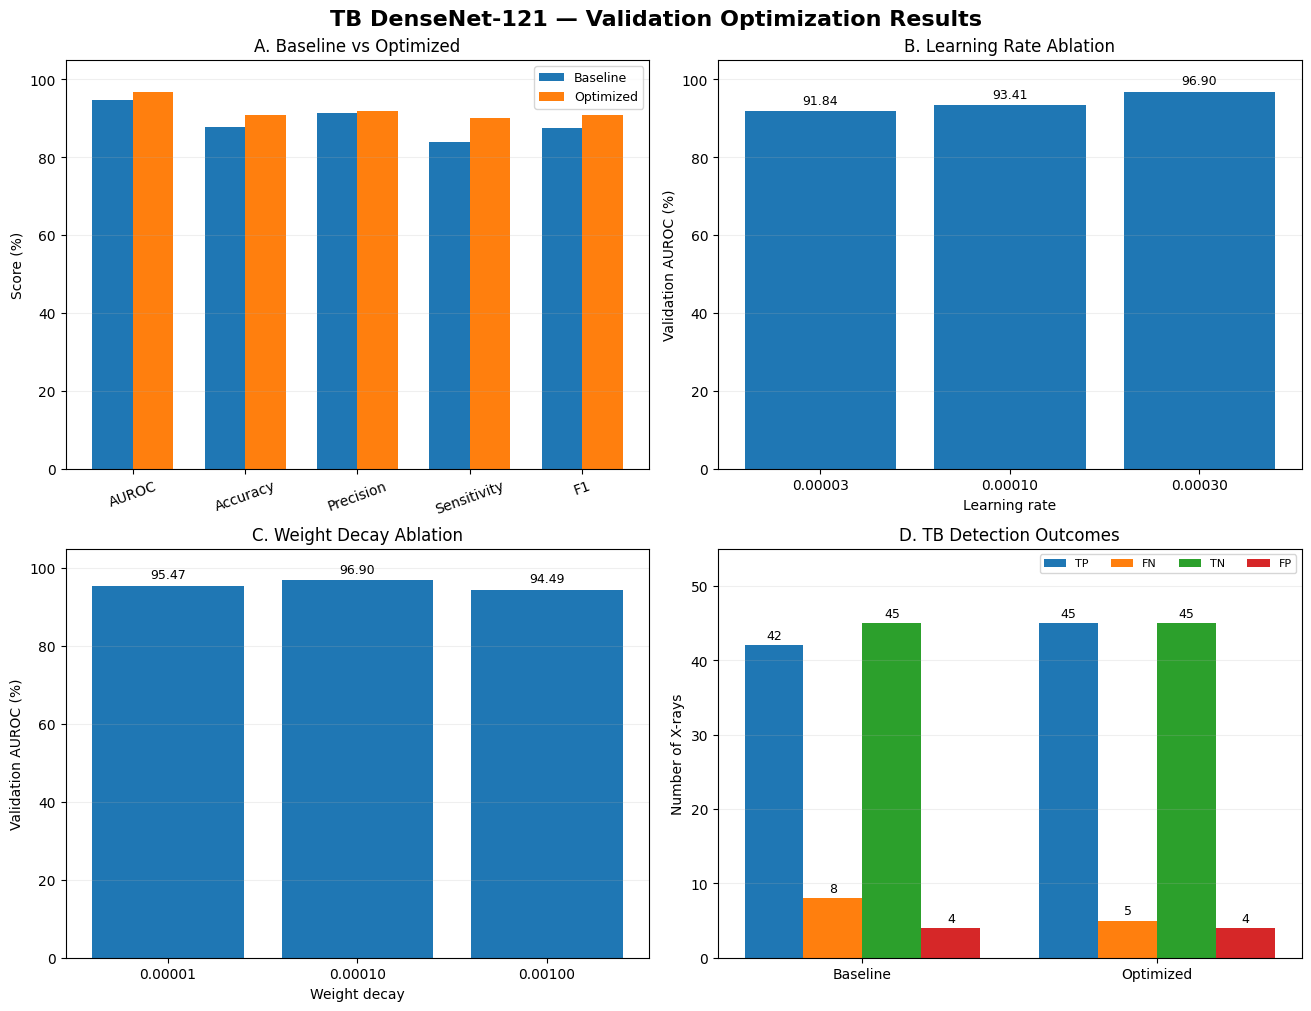

Dashboard saved: /content/drive/MyDrive/Major_Project/Tuberculosis/outputs/optimization/figures/tb_optimization_dashboard_2x2.png


In [10]:

# TB Optimization: Four-Chart Dashboard

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

opt_dir = OUTPUT_DIR / "optimization"
fig_dir = opt_dir / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

# Load Saved Experiment Results
lr_df = pd.read_csv(
    opt_dir / "tb_learning_rate_validation_metrics.csv"
)

wd_df = pd.read_csv(
    opt_dir / "tb_weight_decay_validation_metrics.csv"
)

# Recorded Original Baseline Validation Results
baseline = {
    "AUROC": 0.948163,
    "Accuracy": 0.878788,
    "Precision": 0.913043,
    "Sensitivity": 0.84,
    "F1": 0.875,
    "TN": 45, "FP": 4,
    "FN": 8, "TP": 42
}

# Optimized Model: LR=0.0003, WD=0.0001
optimized = wd_df.loc[
    np.isclose(wd_df["weight_decay"], 0.0001)
    & np.isclose(wd_df["learning_rate"], 0.0003)
].iloc[0]

# Create 2x2 Dashboard
fig, axes = plt.subplots(
    2, 2, figsize=(13, 10),
    constrained_layout=True
)

# Chart 1: Baseline vs Optimized
ax = axes[0, 0]

names = ["AUROC", "Accuracy", "Precision", "Sensitivity", "F1"]
old = [
    baseline["AUROC"],
    baseline["Accuracy"],
    baseline["Precision"],
    baseline["Sensitivity"],
    baseline["F1"]
]
new = [
    optimized["auroc"],
    optimized["accuracy"],
    optimized["precision"],
    optimized["recall_sensitivity"],
    optimized["f1_score"]
]

x = np.arange(len(names))
w = 0.36

ax.bar(x - w/2, np.array(old)*100, w, label="Baseline")
ax.bar(x + w/2, np.array(new)*100, w, label="Optimized")

ax.set_xticks(x)
ax.set_xticklabels(names, rotation=20)
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 105)
ax.set_title("A. Baseline vs Optimized")
ax.legend(fontsize=9)
ax.grid(axis="y", alpha=0.2)

# Chart 2: Learning Rate Ablation
ax = axes[0, 1]
lr_plot = lr_df.sort_values("learning_rate")

bars = ax.bar(
    [f"{v:.5f}" for v in lr_plot["learning_rate"]],
    lr_plot["auroc"] * 100
)

ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_ylim(0, 105)
ax.set_ylabel("Validation AUROC (%)")
ax.set_xlabel("Learning rate")
ax.set_title("B. Learning Rate Ablation")
ax.grid(axis="y", alpha=0.2)

# Chart 3: Weight Decay Ablation
ax = axes[1, 0]
wd_plot = wd_df.sort_values("weight_decay")

bars = ax.bar(
    [f"{v:.5f}" for v in wd_plot["weight_decay"]],
    wd_plot["auroc"] * 100
)

ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_ylim(0, 105)
ax.set_ylabel("Validation AUROC (%)")
ax.set_xlabel("Weight decay")
ax.set_title("C. Weight Decay Ablation")
ax.grid(axis="y", alpha=0.2)

# Chart 4: TB Detection Outcomes
ax = axes[1, 1]

labels = ["Baseline", "Optimized"]
positions = np.arange(2)
width = 0.2

outcomes = {
    "TP": [baseline["TP"], int(optimized["tp"])],
    "FN": [baseline["FN"], int(optimized["fn"])],
    "TN": [baseline["TN"], int(optimized["tn"])],
    "FP": [baseline["FP"], int(optimized["fp"])]
}

for i, (name, values) in enumerate(outcomes.items()):
    bars = ax.bar(
        positions + (i - 1.5) * width,
        values,
        width,
        label=name
    )
    ax.bar_label(bars, padding=2, fontsize=9)

ax.set_xticks(positions)
ax.set_xticklabels(labels)
ax.set_ylabel("Number of X-rays")
ax.set_ylim(0, 55)
ax.set_title("D. TB Detection Outcomes")
ax.legend(ncol=4, fontsize=8)
ax.grid(axis="y", alpha=0.2)

fig.suptitle(
    "TB DenseNet-121 — Validation Optimization Results",
    fontsize=16,
    fontweight="bold"
)

# Save Dashboard
dashboard_path = (
    fig_dir / "tb_optimization_dashboard_2x2.png"
)

plt.savefig(
    dashboard_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Dashboard saved:", dashboard_path)


We performed sequential hyperparameter optimization of DenseNet-121 by evaluating three learning rates and three weight-decay values. The optimal tested configuration was a learning rate of 0.0003 and weight decay of 0.0001, selected using validation AUROC. This configuration improved validation AUROC from 0.9482 to 0.9690 and sensitivity from 84% to 90%.
- Learning rate- 0.00003	0.0001	**0.0003**
- Weight decay- 0.00001	**0.0001**	0.001